<a href="https://colab.research.google.com/github/Angeltt251/Lab_2_8_Regresion_Lineal/blob/main/Lab_2_8_Regresion_Lineal_jose_flores.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Angeltt251/Mineria-de-Datos/blob/main/TU_CARPETA/Lab_2_8_Regresion_Lineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📈 Actividad 2.8 — Laboratorio: Implementación de Regresión Lineal

**Asignatura:** IEI097 Minería de Datos · Unidad II  
**Autor:** José Miguel Flores Chávez · Instituto Profesional Santo Tomás  
**Tipo:** laboratorio individual en Google Colab

**Contenido:** Entorno · Bloque 1 (regresión simple, Breast Cancer) · Bloque 2 (regresión múltiple, FIFA 19) · Bloque 3 (transferencia, vinos blancos)

> Los datasets se descargan con `kagglehub`. Las credenciales se leen desde **Colab Secrets** (`KAGGLE_USERNAME` y `KAGGLE_KEY`) y nunca se escriben en el notebook.

## Entorno

In [1]:
!pip -q install statsmodels kagglehub

In [2]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import kagglehub
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

SEED = 42
print("pandas:", pd.__version__)

pandas: 2.2.3


In [3]:
try:
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    print("Credenciales de Kaggle cargadas desde Colab Secrets ✅")
except Exception as e:
    print("No pude leer los Secrets de Colab (KAGGLE_USERNAME y KAGGLE_KEY). Revisa que existan y que el acceso desde el notebook esté activado.")
    print("Detalle:", type(e).__name__)

No pude leer los Secrets de Colab (KAGGLE_USERNAME y KAGGLE_KEY). Revisa que existan y que el acceso desde el notebook esté activado.
Detalle: SecretNotFoundError


### Funciones de apoyo

Agrupo el código que se repite en los tres bloques: descarga, métricas, gráficos de EDA, gráficos de diagnóstico y VIF.

In [4]:
def descargar_dataset(handle):
    carpeta = kagglehub.dataset_download(handle)
    archivos = sorted(glob.glob(os.path.join(carpeta, "**", "*.csv"), recursive=True))
    print("Dataset:", handle)
    for a in archivos:
        print(f" - {os.path.relpath(a, carpeta)} ({os.path.getsize(a) / 1e6:.2f} MB)")
    return archivos


def elegir_csv(archivos, pista=None):
    if pista:
        coincidencias = [a for a in archivos if pista.lower() in os.path.basename(a).lower()]
        if coincidencias:
            return coincidencias[0]
    return max(archivos, key=os.path.getsize)


def metricas(y_real, y_pred):
    return {"R²": r2_score(y_real, y_pred),
            "MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_real, y_pred)))}


def tabla_metricas(modelo, X_train, y_train, X_test, y_test, nombre):
    filas = []
    for conjunto, X, y in (("entrenamiento", X_train, y_train), ("prueba", X_test, y_test)):
        filas.append({"modelo": nombre, "conjunto": conjunto, **metricas(y, modelo.predict(X))})
    return pd.DataFrame(filas)


def graficos_distribucion(df, columnas, titulo):
    n = len(columnas)
    fig, ejes = plt.subplots(2, n, figsize=(4.2 * n, 6))
    ejes = np.array(ejes).reshape(2, n)
    for j, col in enumerate(columnas):
        sns.histplot(df[col].dropna(), kde=True, ax=ejes[0, j], color="#4C72B0")
        ejes[0, j].set_title(f"Distribución de {col}")
        sns.boxplot(x=df[col].dropna(), ax=ejes[1, j], color="#DD8452")
        ejes[1, j].set_title(f"Box-plot de {col}")
    fig.suptitle(titulo, y=1.01)
    plt.tight_layout()
    plt.show()


def mapa_correlaciones(df, columnas, titulo):
    corr = df[columnas].corr()
    lado = max(6, 0.75 * len(columnas) + 2)
    fig, ax = plt.subplots(figsize=(lado, lado * 0.85))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.8})
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()
    return corr


def barras_correlacion(serie, titulo, n=15):
    top = serie.head(n)[::-1]
    fig, ax = plt.subplots(figsize=(7, 0.35 * len(top) + 1.5))
    ax.barh(top.index, top.values, color=["#C44E52" if v < 0 else "#4C72B0" for v in top.values])
    ax.set_title(titulo)
    ax.set_xlabel("Correlación (Pearson)")
    plt.tight_layout()
    plt.show()


def grafico_regresion(df, x, y, titulo, muestra=3000):
    datos = df[[x, y]].dropna()
    if len(datos) > muestra:
        datos = datos.sample(muestra, random_state=SEED)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    sns.regplot(data=datos, x=x, y=y, ax=ax, scatter_kws={"alpha": 0.35, "s": 14}, line_kws={"color": "red"})
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()


def diagnostico_residuos(y_real, y_pred, titulo):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    residuos = y_real - y_pred
    fig, ejes = plt.subplots(1, 3, figsize=(16, 4.2))
    ejes[0].scatter(y_pred, residuos, s=12, alpha=0.4)
    ejes[0].axhline(0, color="red")
    ejes[0].set_xlabel("Valores predichos")
    ejes[0].set_ylabel("Residuos")
    ejes[0].set_title("Residuos vs. predichos")
    ejes[1].scatter(y_pred, y_real, s=12, alpha=0.4)
    limites = [min(y_pred.min(), y_real.min()), max(y_pred.max(), y_real.max())]
    ejes[1].plot(limites, limites, color="red")
    ejes[1].set_xlabel("Valores predichos")
    ejes[1].set_ylabel("Valores reales")
    ejes[1].set_title("Reales vs. predichos")
    stats.probplot(residuos, dist="norm", plot=ejes[2])
    ejes[2].set_title("Q-Q plot de los residuos")
    fig.suptitle(titulo, y=1.03)
    plt.tight_layout()
    plt.show()


def calcular_vif(df, columnas):
    X = add_constant(df[columnas].astype(float))
    valores = [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])]
    return pd.Series(valores, index=columnas, name="VIF").sort_values(ascending=False)


def eliminar_por_vif(df, columnas, umbral):
    columnas = list(columnas)
    pasos = []
    while len(columnas) > 2:
        vif = calcular_vif(df, columnas)
        if vif.iloc[0] <= umbral:
            break
        pasos.append({"variable eliminada": vif.index[0], "VIF": float(vif.iloc[0]), "variables restantes": len(columnas) - 1})
        columnas.remove(vif.index[0])
    return columnas, pd.DataFrame(pasos)


def metricas_por_grupo(y_real, y_pred, grupos):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    grupos = pd.Series(np.asarray(grupos, dtype=object))
    filas = []
    for g in sorted(grupos.dropna().unique()):
        mascara = (grupos == g).values
        filas.append({"grupo": g, "n": int(mascara.sum()), **metricas(y_real[mascara], y_pred[mascara])})
    return pd.DataFrame(filas)


def boxplot_residuos_por_grupo(y_real, y_pred, grupos, titulo):
    tabla = pd.DataFrame({"residuo": np.asarray(y_real, dtype=float) - np.asarray(y_pred, dtype=float),
                          "grupo": np.asarray(grupos, dtype=object)}).dropna()
    fig, ax = plt.subplots(figsize=(8, 4.2))
    sns.boxplot(data=tabla, x="grupo", y="residuo", ax=ax, color="#8172B3")
    ax.axhline(0, color="red")
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

## Bloque 1 · Regresión lineal simple con Breast Cancer

### Carga e inspección

In [5]:
archivos_bc = descargar_dataset("uciml/breast-cancer-wisconsin-data")
csv_bc = elegir_csv(archivos_bc)
print("\nCSV principal elegido:", os.path.basename(csv_bc))

df_bc = pd.read_csv(csv_bc)
print("Dimensiones:", df_bc.shape)
df_bc.head()

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Dataset: uciml/breast-cancer-wisconsin-data
 - data.csv (0.13 MB)

CSV principal elegido: data.csv
Dimensiones: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,...,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,...,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,...,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,...,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,...,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,...,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [6]:
df_bc.info()

nulos_bc = df_bc.isna().sum()
print("\nColumnas con valores nulos:")
print(nulos_bc[nulos_bc > 0].to_string() if (nulos_bc > 0).any() else "ninguna")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

### Columnas que se descartan

| Columna | Motivo |
|---|---|
| `id` | Identificador del paciente: no es una medición. |
| `diagnosis` | Etiqueta categórica (M/B), no una medición de los núcleos celulares. |
| `Unnamed: 32` | Columna vacía (100 % nula) que aparece al exportar el CSV. |

In [7]:
NO_MEDICIONES_BC = ["id", "diagnosis", "Unnamed: 32"]
df_bc = df_bc.drop(columns=[c for c in NO_MEDICIONES_BC if c in df_bc.columns])

print("Dimensiones tras descartar:", df_bc.shape)
print("Todas las columnas son numéricas:", all(pd.api.types.is_numeric_dtype(t) for t in df_bc.dtypes))
print("Nulos restantes:", int(df_bc.isna().sum().sum()))

Dimensiones tras descartar: (569, 30)
Todas las columnas son numéricas: True
Nulos restantes: 0


### EDA del ejercicio

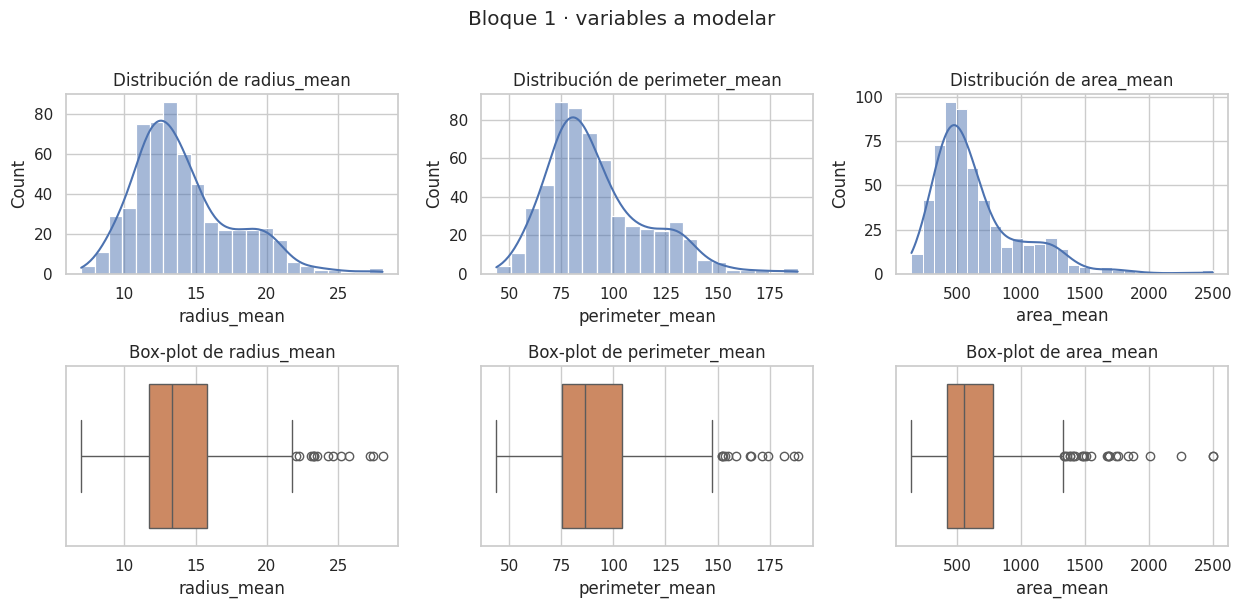

,radius_mean,perimeter_mean,area_mean
count,569.000,569.000,569.000
mean,14.127,91.969,654.889
std,3.524,24.299,351.914
min,6.981,43.790,143.500
25%,11.700,75.170,420.300
50%,13.370,86.240,551.100
75%,15.780,104.100,782.700
max,28.110,188.500,2501.000


In [8]:
VARS_B1 = ["radius_mean", "perimeter_mean", "area_mean"]
graficos_distribucion(df_bc, VARS_B1, "Bloque 1 · variables a modelar")
df_bc[VARS_B1].describe().round(3)

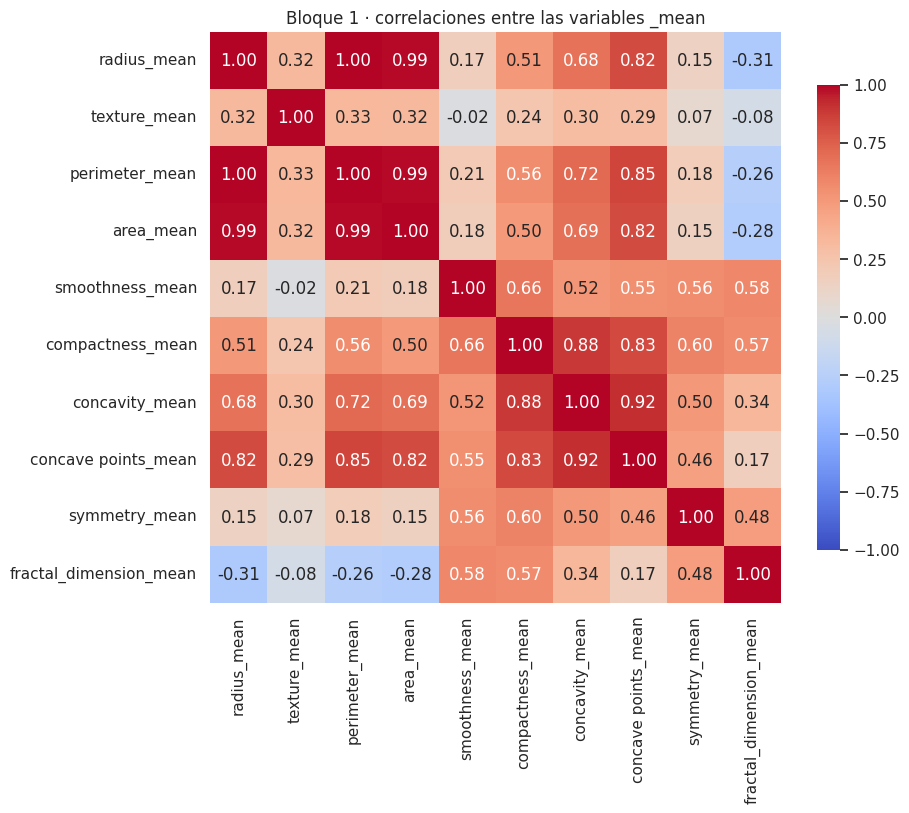

Correlación de cada variable con radius_mean (de mayor a menor):
perimeter_mean            0.998
area_mean                 0.987
concave points_mean       0.823
concavity_mean            0.677
compactness_mean          0.506
texture_mean              0.324
smoothness_mean           0.171
symmetry_mean             0.148
fractal_dimension_mean   -0.312


In [9]:
columnas_media = [c for c in df_bc.columns if c.endswith("_mean")]
corr_bc = mapa_correlaciones(df_bc, columnas_media, "Bloque 1 · correlaciones entre las variables _mean")

print("Correlación de cada variable con radius_mean (de mayor a menor):")
print(corr_bc["radius_mean"].drop("radius_mean").sort_values(ascending=False).round(3).to_string())

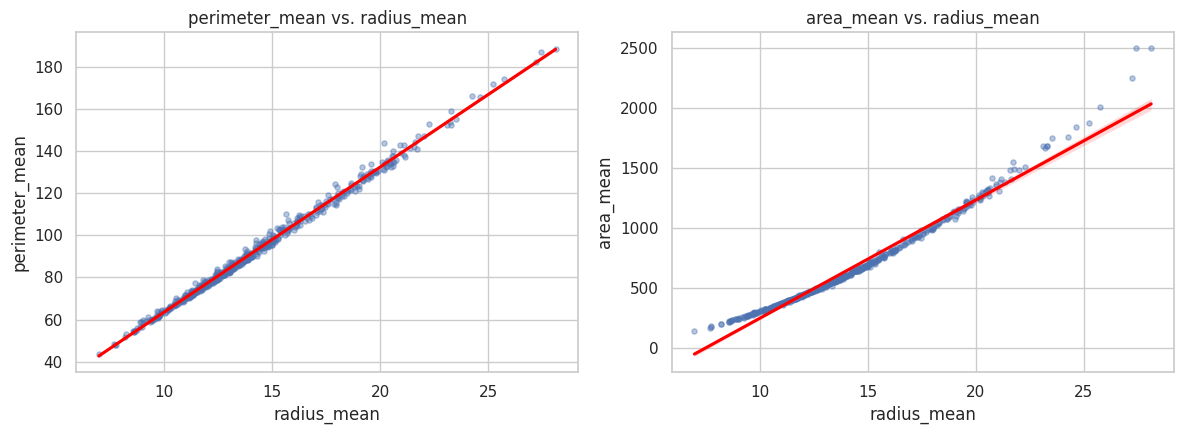

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, objetivo in zip(ejes, ["perimeter_mean", "area_mean"]):
    sns.regplot(data=df_bc, x="radius_mean", y=objetivo, ax=ax, scatter_kws={"alpha": 0.4, "s": 14}, line_kws={"color": "red"})
    ax.set_title(f"{objetivo} vs. radius_mean")
plt.tight_layout()
plt.show()

✍️ **Variables de mayor importancia** *(borrador: confírmalo con tu mapa de correlaciones y reescríbelo con tus palabras)*

`radius_mean`, `perimeter_mean` y `area_mean` miden el tamaño del núcleo celular y están fuertemente correlacionadas entre sí. Por eso `radius_mean` es un predictor razonable para las otras dos.

### Modelos simples y evaluación

Partición 80/20 con `random_state` fijo. La recta se ajusta solo con el conjunto de entrenamiento y se evalúa en el de prueba.

In [ ]:
train_bc, test_bc = train_test_split(df_bc, test_size=0.2, random_state=SEED)
print("Entrenamiento:", train_bc.shape, "| Prueba:", test_bc.shape)

modelos_bc = {}
for objetivo in ["perimeter_mean", "area_mean"]:
    modelos_bc[objetivo] = LinearRegression().fit(train_bc[["radius_mean"]], train_bc[objetivo])

resumen_bc = pd.DataFrame({
    "objetivo": list(modelos_bc.keys()),
    "pendiente": [m.coef_[0] for m in modelos_bc.values()],
    "intercepto": [m.intercept_ for m in modelos_bc.values()],
})
resumen_bc.round(4)

In [ ]:
for objetivo, modelo in modelos_bc.items():
    print(f"{objetivo} = {modelo.coef_[0]:.4f} × radius_mean + ({modelo.intercept_:.4f})")
    print(f"  Pendiente : por cada unidad más de radius_mean, {objetivo} cambia en promedio {modelo.coef_[0]:.3f} unidades.")
    print(f"  Intercepto: con radius_mean = 0 el modelo predice {modelo.intercept_:.3f}.\n")

✍️ **Interpretación de pendiente e intercepto** *(borrador: contrástalo con los valores impresos arriba y reescríbelo con tus palabras)*

- **Modelo del perímetro:** en un círculo perfecto el perímetro es 2·π·r, es decir, una pendiente de 6,28 y un intercepto de 0. Compara con tu pendiente: si es algo mayor, los contornos de los núcleos son más irregulares que un círculo. El intercepto debería ser pequeño frente a los perímetros típicos del dataset.
- **Modelo del área:** el área de un círculo es π·r², una relación cuadrática. La pendiente de la recta es entonces una tasa de cambio promedio, y el intercepto negativo no tiene sentido físico: es un efecto de forzar una recta sobre una curva.

In [ ]:
tablas = []
for objetivo, modelo in modelos_bc.items():
    tablas.append(tabla_metricas(modelo, train_bc[["radius_mean"]], train_bc[objetivo],
                                 test_bc[["radius_mean"]], test_bc[objetivo], objetivo))
metricas_bc = pd.concat(tablas, ignore_index=True)
metricas_bc.round(4)

### Visualización: regresión y residuos

In [ ]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 9))
for fila, (objetivo, modelo) in enumerate(modelos_bc.items()):
    x_test = test_bc[["radius_mean"]]
    y_test = test_bc[objetivo]
    pred = modelo.predict(x_test)
    orden = np.argsort(x_test["radius_mean"].values)

    ejes[fila, 0].scatter(x_test["radius_mean"], y_test, s=16, alpha=0.6, label="datos de prueba")
    ejes[fila, 0].plot(x_test["radius_mean"].values[orden], pred[orden], color="red", label="recta ajustada")
    ejes[fila, 0].set_xlabel("radius_mean")
    ejes[fila, 0].set_ylabel(objetivo)
    ejes[fila, 0].set_title(f"Regresión: {objetivo} ~ radius_mean")
    ejes[fila, 0].legend()

    ejes[fila, 1].scatter(pred, y_test - pred, s=16, alpha=0.6)
    ejes[fila, 1].axhline(0, color="red")
    ejes[fila, 1].set_xlabel("Valores predichos")
    ejes[fila, 1].set_ylabel("Residuos")
    ejes[fila, 1].set_title(f"Residuos vs. predichos: {objetivo}")
plt.tight_layout()
plt.show()

### Pregunta guía: ¿un R² alto es suficiente para concluir que una recta es el modelo adecuado?

✍️ *Borrador: confírmalo con tus gráficos de residuos y reescríbelo con tus palabras.*

No. El R² solo dice qué parte de la variación explica la recta, no si la forma de la relación es realmente lineal.

- En el modelo del **perímetro**, los residuos deberían formar una nube sin forma alrededor de 0: la recta es adecuada.
- En el modelo del **área**, aunque el R² también sea alto, los residuos deberían dibujar una curva en forma de U. Eso indica errores sistemáticos: la recta sobreestima el área en el centro del rango de tamaños y la subestima en los extremos, porque la relación real es cuadrática.

Un R² alto con residuos que muestran un patrón significa que la recta no es el modelo adecuado y que hace falta otra forma funcional o una transformación.

## Bloque 2 · Regresión lineal múltiple con FIFA 19

### Carga y EDA

In [ ]:
archivos_fifa = descargar_dataset("karangadiya/fifa19")
csv_fifa = elegir_csv(archivos_fifa)
print("\nCSV principal elegido:", os.path.basename(csv_fifa))

df_fifa = pd.read_csv(csv_fifa, low_memory=False)
print("Dimensiones:", df_fifa.shape)
df_fifa.head()

In [ ]:
print("Tipos de dato:")
print(df_fifa.dtypes.value_counts().to_string())

nulos_fifa = df_fifa.isna().sum()
print("\nColumnas con más nulos (top 10):")
print(nulos_fifa[nulos_fifa > 0].sort_values(ascending=False).head(10).to_string())

In [ ]:
OBJ_B2 = "Overall"
IDENTIFICADORES_B2 = ["Unnamed: 0", "ID"]

numericas_fifa = df_fifa.select_dtypes("number").columns.difference(IDENTIFICADORES_B2 + [OBJ_B2])
corr_overall = (df_fifa[numericas_fifa].corrwith(df_fifa[OBJ_B2])
                .sort_values(key=lambda s: s.abs(), ascending=False))

barras_correlacion(corr_overall, "Bloque 2 · correlación de cada variable numérica con Overall", n=20)
corr_overall.head(15).round(3)

In [ ]:
graficos_distribucion(df_fifa, [OBJ_B2] + list(corr_overall.index[:3]), "Bloque 2 · Overall y las tres variables más correlacionadas")

In [ ]:
columnas_mapa = [OBJ_B2] + list(corr_overall.index[:10])
corr_b2 = mapa_correlaciones(df_fifa, columnas_mapa, "Bloque 2 · correlaciones: Overall y las 10 variables más correlacionadas")

In [ ]:
mas_correlacionada_b2 = corr_overall.index[0]
grafico_regresion(df_fifa, mas_correlacionada_b2, OBJ_B2, f"Overall vs. {mas_correlacionada_b2} (muestra de 3.000 jugadores)")

✍️ **Variables de mayor importancia** *(borrador: confírmalo con el gráfico de barras y el mapa de correlaciones, y reescríbelo con tus palabras)*

El gráfico de barras ordena todas las variables numéricas por su correlación con `Overall`. Las que aparecen primero son las candidatas naturales; antes de usarlas hay que aplicarles la pregunta de control de data leakage.

### Selección de predictores y data leakage

Pregunta de control para cada candidata: ¿existiría esta variable antes de conocer el `Overall`? ¿Se calcula a partir de él o ambos provienen de la misma fuente?

Variables que **descarto** y por qué *(borrador: revisa cada motivo y reescríbelo si no estás de acuerdo)*:

In [ ]:
DESCARTADAS_B2 = {
    "Potential": "Se estima a partir del Overall actual y de la edad: proviene de la misma fuente que el objetivo.",
    "Special": "Suma los mismos atributos que se usan como predictores: es redundante con ellos.",
    "Value": "Valor de mercado: es consecuencia del Overall, no existe antes de conocerlo. Además viene como texto.",
    "Wage": "Salario: es consecuencia del Overall. Además viene como texto.",
    "Release Clause": "Cláusula de rescisión: se fija a partir del valor del jugador, que depende del Overall. Además viene como texto.",
}

candidatas_b2 = [v for v in corr_overall.index if v not in DESCARTADAS_B2][:12]

registro_b2 = pd.concat([
    pd.DataFrame([{"variable": v, "decisión": "descartada", "correlación con Overall": corr_overall.get(v, np.nan), "motivo": m}
                  for v, m in DESCARTADAS_B2.items()]),
    pd.DataFrame([{"variable": v, "decisión": "candidata", "correlación con Overall": corr_overall[v],
                   "motivo": "Existe antes de conocer el Overall y no se calcula a partir de él."} for v in candidatas_b2]),
], ignore_index=True)

print(f"Candidatas: {len(candidatas_b2)} variables numéricas")
registro_b2.round(3)

### Multicolinealidad: correlación entre predictores y VIF

In [ ]:
datos_b2 = df_fifa[[OBJ_B2, "Position"] + candidatas_b2].dropna(subset=[OBJ_B2] + candidatas_b2).copy()
print(f"Filas completas: {len(datos_b2):,} de {len(df_fifa):,} (se pierden {len(df_fifa) - len(datos_b2):,} por nulos en las variables usadas)")

mapa_correlaciones(datos_b2, candidatas_b2, "Bloque 2 · correlación entre los predictores candidatos")
vif_inicial_b2 = calcular_vif(datos_b2, candidatas_b2)
vif_inicial_b2.round(2).to_frame()

In [ ]:
UMBRAL_VIF = 10

predictores_b2, pasos_vif_b2 = eliminar_por_vif(datos_b2, candidatas_b2, UMBRAL_VIF)

if len(pasos_vif_b2):
    print(f"Variables eliminadas por VIF > {UMBRAL_VIF}, una a la vez (siempre la de mayor VIF):")
    display(pasos_vif_b2.round(2))
else:
    print(f"Ninguna variable supera VIF = {UMBRAL_VIF}.")

print("\nPredictores finales:", predictores_b2)
calcular_vif(datos_b2, predictores_b2).round(2).to_frame()

✍️ **Decisión sobre multicolinealidad** *(escríbela con tus palabras)*

Guía: ¿qué variables eliminó el criterio de VIF y por qué tiene sentido que estén redundantes con otras (por ejemplo, atributos que miden habilidades parecidas)? ¿Mantienes alguna con VIF alto porque es clave para el problema? Justifica.

### Modelo múltiple y métricas

In [ ]:
train_b2, test_b2 = train_test_split(datos_b2, test_size=0.2, random_state=SEED)

modelo_b2 = LinearRegression().fit(train_b2[predictores_b2], train_b2[OBJ_B2])
metricas_b2 = tabla_metricas(modelo_b2, train_b2[predictores_b2], train_b2[OBJ_B2],
                             test_b2[predictores_b2], test_b2[OBJ_B2], "regresión múltiple Overall")
print(f"Intercepto: {modelo_b2.intercept_:.3f}")
metricas_b2.round(4)

In [ ]:
UNIDADES_B2 = {"Age": "año", "International Reputation": "punto de la escala 1-5", "Skill Moves": "punto de la escala 1-5",
               "Weak Foot": "punto de la escala 1-5"}

coef_b2 = pd.DataFrame({
    "coeficiente": modelo_b2.coef_,
    "desv. estándar del predictor": train_b2[predictores_b2].std().values,
}, index=predictores_b2)
coef_b2["efecto de +1 desv. estándar"] = coef_b2["coeficiente"] * coef_b2["desv. estándar del predictor"]
coef_b2 = coef_b2.sort_values("efecto de +1 desv. estándar", key=lambda s: s.abs(), ascending=False)
coef_b2.round(4)

In [ ]:
print("Coeficientes con mayor efecto, leídos con sus unidades (Overall se mide en puntos):\n")
for variable in coef_b2.index[:3]:
    unidad = UNIDADES_B2.get(variable, "punto del atributo")
    c = coef_b2.loc[variable, "coeficiente"]
    print(f"- {variable}: por cada {unidad} adicional, Overall cambia {c:+.3f} puntos en promedio, manteniendo constantes las demás variables.")

✍️ **Interpretación de al menos tres coeficientes y de las métricas** *(escríbela con tus palabras)*

Guía: elige tres coeficientes de la tabla y explica el signo, la magnitud y la unidad. Después compara R², MAE y RMSE entre entrenamiento y prueba: ¿hay sobreajuste? ¿Qué significa un MAE de ese tamaño en puntos de Overall?

In [ ]:
mejor_b2 = corr_overall[predictores_b2].abs().idxmax()
grafico_regresion(datos_b2, mejor_b2, OBJ_B2, f"Overall vs. {mejor_b2}, el predictor más correlacionado (muestra de 3.000)")

pred_b2 = modelo_b2.predict(test_b2[predictores_b2])
diagnostico_residuos(test_b2[OBJ_B2], pred_b2, "Bloque 2 · modelo múltiple en el conjunto de prueba")

### Heterogeneidad: métricas por posición de juego

Defino cuatro subgrupos a partir de la columna `Position`: arqueros, defensas, mediocampistas y delanteros.

In [ ]:
def grupo_posicion(pos):
    if pos == "GK":
        return "Arquero"
    if pos in {"CB", "LB", "RB", "LCB", "RCB", "LWB", "RWB"}:
        return "Defensa"
    if pos in {"CDM", "CM", "CAM", "LM", "RM", "LDM", "RDM", "LCM", "RCM", "LAM", "RAM"}:
        return "Mediocampista"
    if pos in {"ST", "CF", "LW", "RW", "LF", "RF", "LS", "RS"}:
        return "Delantero"
    return np.nan


grupos_test_b2 = test_b2["Position"].map(grupo_posicion)

print("Jugadores de prueba por grupo:")
print(grupos_test_b2.value_counts(dropna=False).to_string())
metricas_grupo_b2 = metricas_por_grupo(test_b2[OBJ_B2], pred_b2, grupos_test_b2)
metricas_grupo_b2.round(4)

In [ ]:
boxplot_residuos_por_grupo(test_b2[OBJ_B2], pred_b2, grupos_test_b2, "Bloque 2 · residuos por grupo de posición")

✍️ **Comentario comparativo por subgrupo** *(escríbelo con tus palabras)*

Guía: compara R², MAE y RMSE entre grupos y con el resultado global. ¿Hay un grupo donde el modelo falle de forma sistemática (residuos centrados lejos de 0)? Piensa qué atributos determinan el Overall de cada posición y si están entre tus predictores (por ejemplo, los atributos `GK...` de los arqueros).

### Desafío opcional: predecir `Value`

`Value` viene como texto (por ejemplo `€110.5M` o `€565K`). Lo convierto a número, observo su distribución y comparo un modelo con `Value` directo contra uno con `log(1 + Value)`.

In [ ]:
def valor_a_numero(texto):
    t = str(texto).replace("€", "").strip()
    if t in ("", "nan"):
        return np.nan
    multiplo = 1.0
    if t.endswith("M"):
        multiplo, t = 1e6, t[:-1]
    elif t.endswith("K"):
        multiplo, t = 1e3, t[:-1]
    return float(t) * multiplo


df_fifa["Value_num"] = df_fifa["Value"].map(valor_a_numero)
print("Valores nulos tras convertir:", int(df_fifa["Value_num"].isna().sum()))
print("Jugadores con valor 0:", int((df_fifa["Value_num"] == 0).sum()))

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(df_fifa["Value_num"].dropna() / 1e6, bins=60, ax=ejes[0], color="#4C72B0")
ejes[0].set_title("Value (millones de €)")
sns.histplot(np.log1p(df_fifa["Value_num"].dropna()), bins=60, ax=ejes[1], color="#55A868")
ejes[1].set_title("log(1 + Value)")
sns.boxplot(x=df_fifa["Value_num"].dropna() / 1e6, ax=ejes[2], color="#DD8452")
ejes[2].set_title("Box-plot de Value (millones de €)")
plt.tight_layout()
plt.show()

In [ ]:
PRED_VALUE = ["Overall", "Potential", "Age", "International Reputation"]
datos_value = df_fifa[["Value_num"] + PRED_VALUE].dropna()
train_v, test_v = train_test_split(datos_value, test_size=0.2, random_state=SEED)

modelo_v_directo = LinearRegression().fit(train_v[PRED_VALUE], train_v["Value_num"])
modelo_v_log = LinearRegression().fit(train_v[PRED_VALUE], np.log1p(train_v["Value_num"]))

pred_directo = modelo_v_directo.predict(test_v[PRED_VALUE])
pred_log = np.expm1(modelo_v_log.predict(test_v[PRED_VALUE]))

comparacion_value = pd.DataFrame({
    "modelo": ["Value directo", "log(1 + Value)"],
    "R² (escala original)": [r2_score(test_v["Value_num"], pred_directo), r2_score(test_v["Value_num"], pred_log)],
    "MAE (millones de €)": [mean_absolute_error(test_v["Value_num"], pred_directo) / 1e6, mean_absolute_error(test_v["Value_num"], pred_log) / 1e6],
    "RMSE (millones de €)": [np.sqrt(mean_squared_error(test_v["Value_num"], pred_directo)) / 1e6, np.sqrt(mean_squared_error(test_v["Value_num"], pred_log)) / 1e6],
})
comparacion_value.round(4)

✍️ **Comentario del desafío** *(escríbelo con tus palabras)*

Guía: ¿qué forma tiene la distribución de `Value`? ¿Mejoró el modelo con la transformación logarítmica en la escala original? ¿Por qué un valor de mercado suele crecer de forma multiplicativa y no lineal con el Overall?

## Bloque 3 · Transferencia a mi dataset (vinos blancos)

Dataset del Laboratorio 01: `willianoliveiragibin/modeling-wine` (archivo de vinos blancos).

### Carga y limpieza

In [ ]:
archivos_vino = descargar_dataset("willianoliveiragibin/modeling-wine")
csv_vino = elegir_csv(archivos_vino, pista="white")
print("\nCSV principal elegido:", os.path.basename(csv_vino))

df_vino = pd.read_csv(csv_vino, sep=None, engine="python")
df_vino.columns = df_vino.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)
print("Dimensiones:", df_vino.shape)
print("Columnas:", list(df_vino.columns))
df_vino.head()

In [ ]:
df_vino = df_vino.drop(columns=[c for c in df_vino.columns if c.startswith("unnamed") or c == "id"])

no_numericas = df_vino.select_dtypes(exclude="number").columns.tolist()
print("Columnas no numéricas descartadas:", no_numericas if no_numericas else "ninguna")
df_vino = df_vino.drop(columns=no_numericas)

print("Nulos:", int(df_vino.isna().sum().sum()))
n_duplicadas = int(df_vino.duplicated().sum())
df_vino = df_vino.drop_duplicates().reset_index(drop=True)
print(f"Filas duplicadas eliminadas: {n_duplicadas} | filas finales: {len(df_vino):,}")
df_vino.describe().round(3)

### Variable objetivo

Elijo **`density`** (densidad del vino, en g/cm³): es una variable numérica continua y tiene una relación física esperable con otras mediciones del dataset, como el alcohol y el azúcar residual. Descarto `quality` como objetivo porque es una nota entera de 0 a 10 (ordinal), no una variable continua.

✍️ *Si prefieres otra variable continua (por ejemplo `alcohol`), cambia `OBJ_B3` en la celda siguiente y vuelve a ejecutar desde ahí.*

In [ ]:
OBJ_B3 = "density"
assert OBJ_B3 in df_vino.columns, f"No existe la columna {OBJ_B3}. Columnas disponibles: {list(df_vino.columns)}"

otras_b3 = df_vino.columns.difference([OBJ_B3])
corr_b3 = df_vino[otras_b3].corrwith(df_vino[OBJ_B3]).sort_values(key=lambda s: s.abs(), ascending=False)
print(f"Correlación de cada variable con {OBJ_B3}:")
corr_b3.round(3).to_frame("correlación")

### EDA propio

In [ ]:
graficos_distribucion(df_vino, [OBJ_B3] + list(corr_b3.index[:3]), f"Bloque 3 · {OBJ_B3} y las tres variables más correlacionadas")

In [ ]:
mapa_correlaciones(df_vino, list(df_vino.columns), "Bloque 3 · correlaciones entre todas las variables numéricas")
barras_correlacion(corr_b3, f"Bloque 3 · correlación de cada variable con {OBJ_B3}", n=len(corr_b3))

In [ ]:
mas_correlacionada_b3 = corr_b3.index[0]
grafico_regresion(df_vino, mas_correlacionada_b3, OBJ_B3, f"{OBJ_B3} vs. {mas_correlacionada_b3}")

✍️ **Variables de mayor importancia** *(escríbelo con tus palabras)*

Guía: según el mapa y el gráfico de barras, ¿qué variables tienen mayor correlación con la densidad? ¿Tiene sentido físico (el azúcar aumenta la densidad y el alcohol la disminuye)?

### Selección de predictores y data leakage

Aplico la pregunta de control a cada variable. Todas las mediciones fisicoquímicas se determinan en laboratorio de forma independiente de la densidad. La excepción es **`quality`**: es una nota que asignan catadores después de evaluar el vino, no una medición previa, y además es ordinal. La descarto como predictor *(borrador: reescríbelo con tus palabras)*.

In [ ]:
DESCARTADAS_B3 = {"quality": "Nota de catadores asignada después de evaluar el vino; no es una medición previa y es ordinal."}

candidatas_b3 = [v for v in otras_b3 if v not in DESCARTADAS_B3]

registro_b3 = pd.concat([
    pd.DataFrame([{"variable": v, "decisión": "descartada", "correlación con objetivo": corr_b3.get(v, np.nan), "motivo": m}
                  for v, m in DESCARTADAS_B3.items() if v in df_vino.columns]),
    pd.DataFrame([{"variable": v, "decisión": "candidata", "correlación con objetivo": corr_b3[v],
                   "motivo": "Medición de laboratorio independiente del objetivo."} for v in candidatas_b3]),
], ignore_index=True)
registro_b3.round(3)

### Multicolinealidad

In [ ]:
mapa_correlaciones(df_vino, candidatas_b3, "Bloque 3 · correlación entre los predictores candidatos")

predictores_b3, pasos_vif_b3 = eliminar_por_vif(df_vino, candidatas_b3, UMBRAL_VIF)

print("VIF de los candidatos:")
display(calcular_vif(df_vino, candidatas_b3).round(2).to_frame())

if len(pasos_vif_b3):
    print(f"Variables eliminadas por VIF > {UMBRAL_VIF}:")
    display(pasos_vif_b3.round(2))
else:
    print(f"Ninguna variable supera VIF = {UMBRAL_VIF}: se mantienen todos los candidatos.")
print("\nPredictores finales:", predictores_b3)

✍️ **Decisión sobre multicolinealidad** *(escríbela con tus palabras)*

Guía: ¿qué pares de variables están más correlacionados entre sí? ¿Hay VIF altos? Si no hay variables eliminadas, justifica por qué mantener todas es razonable.

### Modelo, métricas y diagnóstico

In [ ]:
datos_b3 = df_vino[[OBJ_B3] + predictores_b3 + [c for c in ["quality"] if c in df_vino.columns]].copy()
train_b3, test_b3 = train_test_split(datos_b3, test_size=0.2, random_state=SEED)

modelo_b3 = LinearRegression().fit(train_b3[predictores_b3], train_b3[OBJ_B3])
metricas_b3 = tabla_metricas(modelo_b3, train_b3[predictores_b3], train_b3[OBJ_B3],
                             test_b3[predictores_b3], test_b3[OBJ_B3], f"regresión múltiple {OBJ_B3}")
print(f"Intercepto: {modelo_b3.intercept_:.6f}")
metricas_b3.round(6)

In [ ]:
UNIDADES_B3 = {"fixed_acidity": "g/L", "volatile_acidity": "g/L", "citric_acid": "g/L", "residual_sugar": "g/L",
               "chlorides": "g/L", "free_sulfur_dioxide": "mg/L", "total_sulfur_dioxide": "mg/L", "density": "g/cm³",
               "ph": "unidad de pH", "sulphates": "g/L", "alcohol": "% vol"}

coef_b3 = pd.DataFrame({
    "coeficiente": modelo_b3.coef_,
    "unidad del predictor": [UNIDADES_B3.get(v, "unidad de la variable") for v in predictores_b3],
    "desv. estándar del predictor": train_b3[predictores_b3].std().values,
}, index=predictores_b3)
coef_b3["efecto de +1 desv. estándar"] = coef_b3["coeficiente"] * coef_b3["desv. estándar del predictor"]
coef_b3 = coef_b3.sort_values("efecto de +1 desv. estándar", key=lambda s: s.abs(), ascending=False)

pd.options.display.float_format = "{:.6f}".format
display(coef_b3)
pd.reset_option("display.float_format")

In [ ]:
pred_b3 = modelo_b3.predict(test_b3[predictores_b3])
diagnostico_residuos(test_b3[OBJ_B3], pred_b3, f"Bloque 3 · modelo de {OBJ_B3} en el conjunto de prueba")

### Heterogeneidad

In [ ]:
def segmentar_vino(tabla):
    if "quality" in tabla.columns:
        return pd.cut(tabla["quality"], bins=[-np.inf, 5, 6, np.inf], labels=["calidad baja (≤5)", "calidad media (6)", "calidad alta (≥7)"])
    return pd.qcut(tabla["alcohol"], 3, labels=["alcohol bajo", "alcohol medio", "alcohol alto"])


segmento_test_b3 = segmentar_vino(test_b3).astype(object)
print("Segmentación usada:", "calidad del vino" if "quality" in test_b3.columns else "tercil de alcohol")
print(pd.Series(segmento_test_b3).value_counts().to_string())

metricas_segmento_b3 = metricas_por_grupo(test_b3[OBJ_B3], pred_b3, segmento_test_b3)
metricas_segmento_b3.round(6)

In [ ]:
boxplot_residuos_por_grupo(test_b3[OBJ_B3], pred_b3, segmento_test_b3, "Bloque 3 · residuos por segmento")

✍️ **Comentario de heterogeneidad** *(escríbelo con tus palabras)*

Guía: compara R², MAE y RMSE entre segmentos y con el global. ¿Algún segmento tiene residuos centrados lejos de 0 o con más dispersión? Si no hay diferencias relevantes, dilo con la evidencia de la tabla y del box-plot.

### Preguntas de cierre

Datos de apoyo calculados a partir de tu modelo:

In [ ]:
variable_clave = coef_b3.index[0]
unidad_clave = UNIDADES_B3.get(variable_clave, "unidad de la variable")
c_clave = coef_b3.loc[variable_clave, "coeficiente"]
print(f"(a) {variable_clave}: por cada 1 {unidad_clave} adicional, {OBJ_B3} cambia {c_clave:+.6f} {UNIDADES_B3.get(OBJ_B3, 'unidades')} en promedio, "
      f"manteniendo constantes las demás variables.\n")

m_train = metricas_b3[metricas_b3["conjunto"] == "entrenamiento"].iloc[0]
m_test = metricas_b3[metricas_b3["conjunto"] == "prueba"].iloc[0]
print("(b) Error en entrenamiento vs. prueba:")
print(f"    R²   : {m_train['R²']:.4f} vs. {m_test['R²']:.4f}  (diferencia {m_train['R²'] - m_test['R²']:+.4f})")
print(f"    MAE  : {m_train['MAE']:.6f} vs. {m_test['MAE']:.6f}")
print(f"    RMSE : {m_train['RMSE']:.6f} vs. {m_test['RMSE']:.6f}\n")

residuos_b3 = np.asarray(test_b3[OBJ_B3], dtype=float) - pred_b3
print("(c) Evidencia numérica para los supuestos:")
print(f"    Media de los residuos            : {residuos_b3.mean():.2e}  (debería ser cercana a 0)")
print(f"    Asimetría de los residuos        : {stats.skew(residuos_b3):.3f}  (0 en una distribución simétrica)")
print(f"    Curtosis (exceso) de los residuos: {stats.kurtosis(residuos_b3):.3f}  (0 en una normal)")
print(f"    Correlación |residuo| vs. predicho: {np.corrcoef(np.abs(residuos_b3), pred_b3)[0, 1]:.3f}  (lejos de 0 sugiere varianza no constante)")

✍️ **(a) Interpreta un coeficiente de tu modelo indicando sus unidades**

*Escribe aquí tu respuesta.* Guía: signo, magnitud, unidad del predictor, unidad del objetivo y la condición «manteniendo constantes las demás variables».

✍️ **(b) Compara el error en entrenamiento y en prueba y explica qué indica esa diferencia**

*Escribe aquí tu respuesta.* Guía: errores parecidos indican que el modelo generaliza; un error de prueba mucho mayor indica sobreajuste.

✍️ **(c) Identifica un supuesto de la regresión lineal que tu modelo cumple o incumple, con evidencia gráfica**

*Escribe aquí tu respuesta.* Guía: linealidad y varianza constante se revisan en el gráfico de residuos vs. predichos; normalidad de los residuos, en el Q-Q plot; elige uno y cítalo con lo que ves en tus gráficos.